# 🛰️📡 Domínios Satellite, Signal e Tracks — Demonstração End‑to‑End

Este notebook explora as entidades dos três domínios centrais do RadioSkySim:

- **Satellite**: `Satellite`, `OrbitalElement`, `SatelliteAssembled`
- **Signal**: `SignalDefinition`, `SatSignal`, `SignalFactory` (geração de PSDs GNSS)
- **Tracks**: `Tracks` (trajetórias de satélites encapsuladas em xarray)

O fluxo percorre: criação dos modelos → validação → geração de sinais → montagem de tracks → visualização.


In [14]:
# ============================================================
# Imports
# ============================================================
from __future__ import annotations

import sys
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

from astropy.time import Time

# Garante que o src/ está no path
SRC = Path.cwd().resolve().parent / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

# ── Satellite domain ──
from radioskysims.domain.satellite.models import (
    Satellite,
    OrbitalElement,
    SatelliteAssembled,
)

# ── Signal domain ──
from radioskysims.domain.signal.models import SignalDefinition, SatSignal
from radioskysims.domain.signal.factory import SignalFactory

# ── Tracks domain ──
from radioskysims.domain.tracks.models import Tracks

# ── Common ──
from radioskysims.domain.common.models import FrequencyRange

print("✅ Imports OK")
print(f"RadioSkySim SRC: {SRC}")

✅ Imports OK
RadioSkySim SRC: /media/lbarosi/barosi_portable1/RadioSkySim/src


## 1. 🛰️ Domínio Satellite — Modelos e Validação

O domínio `satellite` define três modelos principais:

- **`OrbitalElement`**: Value Object que encapsula TLE e época.
- **`Satellite`**: Entidade com `norad_id`, `name`, `constellation`, `epoch` e `element`. Valida que a diferença entre a época do satélite e a do elemento orbital não ultrapasse 5 dias.
- **`SatelliteAssembled`**: Entidade que combina `tracks` (trajetória) e `signals` (espectros) de um satélite observável.


In [2]:
# ── 1a. Criação de OrbitalElement ──
epoch = datetime(2024, 6, 1, 12, 0, 0, tzinfo=timezone.utc)

orb = OrbitalElement(
    epoch=epoch,
    norad_id=25544,
    tle_line1="1 25544U 98067A   24153.50000000  .00000000  00000+0  00000+0 0  9999",
    tle_line2="2 25544  51.6400  50.0000 0007000  90.0000 270.0000 15.50000000360000",
)
print(f"OrbitalElement: norad_id={orb.norad_id}, epoch={orb.epoch}")

# ── 1b. Criação de Satellite válido ──
sat = Satellite(
    norad_id=25544,
    name="ISS (ZARYA)",
    constellation="ISS",
    epoch=epoch,
    element=orb,
)
print(f"Satellite: {sat.name} (NORAD {sat.norad_id}) — OK")

# ── 1c. Satellite com epoch inválida (diferença > 5 dias) ──
try:
    bad_epoch = datetime(2024, 1, 1, tzinfo=timezone.utc)
    _ = Satellite(
        norad_id=99999,
        epoch=bad_epoch,
        element=orb,  # epoch do elemento é junho, diferença >> 5 dias
    )
except ValueError as e:
    print(f"❌ Validação corretamente rejeitada: {e}")

# ── 1d. Criação de SatelliteAssembled (sem tracks/signals reais ainda) ──
dummy_tracks = xr.Dataset(
    {"theta": ("time", [0.0]), "range": ("time", [0.0])}, coords={"time": [0.0]}
)
dummy_signals = xr.Dataset({"PSD": ("freq", [0.0])}, coords={"freq": [0.0]})

assembled = SatelliteAssembled(
    name="ISS (ZARYA)",
    tracks=dummy_tracks,
    signals=dummy_signals,
)
print(f"SatelliteAssembled: name={assembled.name}")
print(f"  angle() → {assembled.angle().values}")
print(f"  psd()   → {assembled.psd().values}")

OrbitalElement: norad_id=25544, epoch=2024-06-01 12:00:00+00:00
Satellite: ISS (ZARYA) (NORAD 25544) — OK
❌ Validação corretamente rejeitada: 1 validation error for Satellite
  Value error, Epoch inconsistente: diferença de 152.50 dias excede o limite de 5 dias. [type=value_error, input_value={'norad_id': 99999, 'epoc...000 15.50000000360000')}, input_type=dict]
    For further information visit https://errors.pydantic.dev/2.11/v/value_error
SatelliteAssembled: name=ISS (ZARYA)
  angle() → [0.]
  psd()   → [0.]


## 2. 📡 Domínio Signal — Definições e Geração de PSD

O domínio `signal` modela os sinais transmitidos por satélites GNSS:

- **`SignalDefinition`**: Definição de um sinal (modulação, frequência da portadora em MHz, comprimento PRN).
- **`SatSignal`**: Value Object que vincula `SignalDefinition` a uma PSD lazy (`dask.delayed`).
- **`SignalFactory`**: Gera PSDs para múltiplos satélites usando computação lazy e interpolação no grid de frequências.

Modulações suportadas: **BPSK**, **QPSK**, **BOC**, **CBOC**.


In [3]:
# ── 2a. SignalDefinition ──
# GPS L1 C/A: BPSK(1) em 1575.42 MHz
gps_l1 = SignalDefinition(modulation="BPSK(1)", frequency=1575.42)
print(
    f"GPS L1:   mod={gps_l1.modulation}, fc={gps_l1.frequency} MHz, prn_len={gps_l1.prn_len}"
)

# Galileo E1: CBOC em 1575.42 MHz
gal_e1 = SignalDefinition(modulation="CBOC", frequency=1575.42)
print(f"Gal E1:   mod={gal_e1.modulation}, fc={gal_e1.frequency} MHz")

# GPS L5: BPSK(10) em 1176.45 MHz
gps_l5 = SignalDefinition(modulation="BPSK(10)", frequency=1176.45)
print(f"GPS L5:   mod={gps_l5.modulation}, fc={gps_l5.frequency} MHz")

# ── 2b. SatSignal ──
# Cria SatSignal com PSD mockada
psd_mock = np.zeros(100)
sat_sig = SatSignal(signal=gps_l1, psd=psd_mock)
print(
    f"SatSignal: signal.modulation={sat_sig.signal.modulation}, psd.shape={np.asarray(sat_sig.psd).shape}"
)

# ── 2c. SignalFactory — geração de PSD ──
# Configura grid de frequência de 1200 a 1600 MHz
fr = FrequencyRange(min_mhz=1200.0, max_mhz=1600.0, resolution_mhz=1.0)
print(f"Grid de frequência: {len(fr.value)} pontos de {fr.min} a {fr.max} MHz")

from unittest.mock import MagicMock

mock_repo = MagicMock()
sig_factory = SignalFactory(frequency_range=fr, signal_repo=mock_repo)

grid_hz = sig_factory.frequency_grid_hz()
print(f"Grid em Hz: {grid_hz[0]:.0f} … {grid_hz[-1]:.0f} Hz ({len(grid_hz)} pontos)")

# ── 2d. Geração de PRN e modulações ──
prn = sig_factory._generate_prn(31)
print(f"PRN (31 chips): valores em {{{np.unique(prn).tolist()}}}")

# BPSK
chips = np.array([-1.0, 1.0, -1.0, 1.0])
bpsk_sig = sig_factory._bpsk(chips, sps=4)
print(f"BPSK output: {len(bpsk_sig)} amostras")

# BOC
boc_sig = sig_factory._boc(chips, sps=8, m=1)
print(f"BOC(1,1) output: {len(boc_sig)} amostras")

# CBOC
cboc_sig = sig_factory._cboc(chips, sps=8)
print(f"CBOC output: {len(cboc_sig)} amostras")

GPS L1:   mod=BPSK(1), fc=1575.42 MHz, prn_len=1023
Gal E1:   mod=CBOC, fc=1575.42 MHz
GPS L5:   mod=BPSK(10), fc=1176.45 MHz
SatSignal: signal.modulation=BPSK(1), psd.shape=(100,)
Grid de frequência: 401 pontos de 1200.0 a 1600.0 MHz
Grid em Hz: 1200000000 … 1600000000 Hz (401 pontos)
PRN (31 chips): valores em {[-1.0, 1.0]}
BPSK output: 16 amostras
BOC(1,1) output: 32 amostras
CBOC output: 32 amostras


In [4]:
# ── 2e. Simulação de PSD (lazy) ──
# A PSD é computada lazy via dask.delayed
psd_delayed = sig_factory._simulate_psd(
    modulation="BPSK(1)",
    fc_hz=1575.42e6,
    prn_len=2048,
    fs_factor=8,
)
print(f"Tipo: {type(psd_delayed).__name__} — objeto lazy (dask.delayed)")

# Computa a PSD
psd = psd_delayed.compute()
print(f"PSD computada: shape={psd.shape}, dtype={psd.dtype}")
print(f"PSD min={psd.min():.2f} dB/Hz, max={psd.max():.2f} dB/Hz")

# ── 2f. PSD para BOC ──
psd_boc = sig_factory._simulate_psd(
    modulation="BOC(1,1)",
    fc_hz=1575.42e6,
    prn_len=2048,
    fs_factor=8,
).compute()
print(f"PSD BOC: shape={psd_boc.shape}")

# ── 2g. PSD para CBOC ──
psd_cboc = sig_factory._simulate_psd(
    modulation="CBOC",
    fc_hz=1575.42e6,
    prn_len=2048,
    fs_factor=8,
).compute()
print(f"PSD CBOC: shape={psd_cboc.shape}")

Tipo: Delayed — objeto lazy (dask.delayed)
PSD computada: shape=(401,), dtype=float64
PSD min=-128.79 dB/Hz, max=-63.33 dB/Hz
PSD BOC: shape=(401,)
PSD CBOC: shape=(401,)


## 3. 🛤️ Domínio Tracks — Trajetórias de Satélites

O domínio `tracks` encapsula trajetórias 3D de satélites em um `xarray.Dataset`:

- **`Tracks`**: Value Object Pydantic que valida estrutura (dimensões `satellite`, `time`, `xyz` e variáveis `positions`, `names`, `constellation`).
- **Métodos**: `filter_by_satellite`, `filter_by_constellation`, `filter_by_time`, `to_zarr`, `to_hdf5`, `get_chunks`, `get_chunks_info`.
- Thread-safe com `threading.Lock` e `asyncio.Lock`.


In [5]:
# ── 3a. Criação de Tracks a partir de xarray ──
sat = 4
time = 10
xyz = 3

rng = np.random.RandomState(42)
positions = rng.random_sample((sat, time, xyz))

ds = xr.Dataset(
    {
        "positions": (("satellite", "time", "xyz"), positions),
        "names": ("satellite", [f"S{i}" for i in range(sat)]),
        "constellation": ("satellite", ["GPS", "GAL", "GPS", "GLO"]),
    },
    coords={
        "satellite": np.arange(sat),
        "time": np.arange(time),
        "xyz": ["x", "y", "z"],
    },
)

tracks = Tracks.from_xr(ds)
print(f"Tracks criado com {len(tracks.satellite_names)} satélites")
print(
    f"  dims: satellite={ds.dims['satellite']}, time={ds.dims['time']}, xyz={ds.dims['xyz']}"
)
print(f"  time_range: {tracks.time_range}")

# ── 3b. Validação de estrutura ──
print(f"  variáveis: {set(ds.data_vars) | set(ds.coords)}")

# ── 3c. Filtros ──
gps = tracks.filter_by_constellation("GPS")
print(f"  GPS: {gps.dataset.sizes['satellite']} satélites")

sat0 = tracks.filter_by_satellite(0)
print(f"  Satélite 0: {sat0.dataset.sizes['satellite']} satélite")

t2 = tracks.filter_by_time(start=2, end=5)
print(f"  Tempo [2,5]: {t2.dataset.sizes['time']} amostras")

# ── 3d. Chunk info ──
info = tracks.get_chunks_info("positions")
print(f"  Chunks: {info['chunks']}")
print(f"  Grid: {info['num_chunk_grid']}")

# ── 3e. Summary ──
summary = tracks.summary()
print(f"  Summary: {summary['dims']}")

# ── 3f. Export para Zarr (diretório temporário) ──
import tempfile, os

with tempfile.TemporaryDirectory() as tmp:
    zpath = os.path.join(tmp, "tracks.zarr")
    tracks.to_zarr(zpath)
    assert os.path.exists(zpath)
    print(f"  ✅ Export Zarr: {zpath}")

Tracks criado com 4 satélites
  dims: satellite=4, time=10, xyz=3
  time_range: ('0', '9')
  variáveis: {'xyz', 'names', 'satellite', 'time', 'constellation', 'positions'}
  GPS: 2 satélites
  Satélite 0: 1 satélite
  Tempo [2,5]: 4 amostras
  Chunks: None
  Grid: (1, 1, 1)
  Summary: {'satellite': 4, 'time': 10, 'xyz': 3}


/tmp/ipykernel_198428/2958806689.py:25: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  f"  dims: satellite={ds.dims['satellite']}, time={ds.dims['time']}, xyz={ds.dims['xyz']}"


  ✅ Export Zarr: /tmp/tmp_senm66y/tracks.zarr


/media/lbarosi/barosi_portable1/RadioSkySim/.venv/lib/python3.13/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/media/lbarosi/barosi_portable1/RadioSkySim/.venv/lib/python3.13/site-packages/zarr/core/array.py:4282: UserWarning: The dtype `<U1` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  meta = AsyncArray._create_metadata_v3(
/media/lbarosi/barosi_portable1/RadioSkySim/.venv/lib/python3.13/site-packages/zarr/core/array.py:4282: UserWarning: The dtype `<U2` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  meta = AsyncArray._create_metadata_v3(
/media/lbarosi/barosi_portable1/RadioSkySim/.v

## 4. 🔗 Fluxo End‑to‑End: Montagem do SatelliteAssembled

Agora juntamos os três domínios:

1. **Tracks** → dataset de posições (x, y, z) ao longo do tempo
2. **Signal** → PSDs dos sinais GNSS
3. **SatelliteAssembled** → combina tracks e signals com interface unificada (`angle()`, `range()`, `psd()`)

> *Nota: Em produção, as tracks vêm do Skyfield e as signals do banco de dados. Aqui usamos dados mockados para demonstrar o fluxo.*


In [6]:
# ═══════════════════════════════════════════════
# 4a. Constroi Tracks realistas (numpy)
# ═══════════════════════════════════════════════
n_sats = 3
n_times = 50

# Simula posições orbitais: movimento senoidal em x,y com drift em z
tt = np.linspace(0, 2 * np.pi, n_times)
positions = np.zeros((n_sats, n_times, 3))
for i in range(n_sats):
    phase = i * 2 * np.pi / n_sats
    positions[i, :, 0] = 7000 * np.cos(tt + phase)  # x (km)
    positions[i, :, 1] = 7000 * np.sin(tt + phase)  # y (km)
    positions[i, :, 2] = 500 * np.sin(2 * tt + phase)  # z (km)

track_ds = xr.Dataset(
    {
        "positions": (("satellite", "time", "xyz"), positions),
        "names": ("satellite", ["SAT-A", "SAT-B", "SAT-C"]),
        "constellation": ("satellite", ["GPS", "GPS", "GAL"]),
    },
    coords={
        "satellite": np.arange(n_sats),
        "time": tt,
        "xyz": ["x", "y", "z"],
    },
)
tracks = Tracks.from_xr(track_ds)
print(
    f"✅ Tracks: {tracks.dataset.sizes['satellite']} satélites × {tracks.dataset.sizes['time']} tempos"
)

# ═══════════════════════════════════════════════
# 4b. Gera PSDs para sinais GNSS
# ═══════════════════════════════════════════════
# Grid de frequência GNSS (L1 + L5)
fr_gnss = FrequencyRange(min_mhz=1150.0, max_mhz=1620.0, resolution_mhz=2.0)
mock_repo = MagicMock()
sf = SignalFactory(frequency_range=fr_gnss, signal_repo=mock_repo)
grid_mhz = sf.frequency_grid_hz() * 1e-6

# Gera PSD mock via SignalFactory para GPS L1 (BPSK)
psd_l1 = sf._simulate_psd(
    modulation="BPSK(1)", fc_hz=1575.42e6, prn_len=2048, fs_factor=8
).compute()

# PSD para Galileo E1 (CBOC)
psd_e1 = sf._simulate_psd(
    modulation="CBOC", fc_hz=1575.42e6, prn_len=2048, fs_factor=8
).compute()

print(f"✅ PSD BPSK(1): {psd_l1.shape}, PSD CBOC: {psd_e1.shape}")

# ═══════════════════════════════════════════════
# 4c. Monta SatelliteAssembled
# ═══════════════════════════════════════════════
# Dataset de sinais com PSDs empilhadas
n_freq = len(grid_mhz)
signals_ds = xr.Dataset(
    {
        "PSD": (("satellite", "freq"), np.stack([psd_l1, psd_l1, psd_e1], axis=0)),
    },
    coords={
        "satellite": np.arange(n_sats),
        "freq": grid_mhz,
    },
)

# SatelliteAssembled para cada satélite
assembled_list = []
for i in range(n_sats):
    sat_name = track_ds.names.values[i]
    sat_tracks = tracks.filter_by_satellite(i).dataset
    sat_signals = signals_ds.isel(satellite=i)

    assembled = SatelliteAssembled(
        name=str(sat_name),
        tracks=sat_tracks,
        signals=sat_signals,
    )
    assembled_list.append(assembled)

print(f"✅ {len(assembled_list)} SatelliteAssembled criados")
for a in assembled_list:
    print(
        f"   {a.name}: tracks.time={a.tracks.sizes['time']}, signals.freq={a.signals.sizes['freq']}"
    )

✅ Tracks: 3 satélites × 50 tempos
✅ PSD BPSK(1): (236,), PSD CBOC: (236,)
✅ 3 SatelliteAssembled criados
   SAT-A: tracks.time=50, signals.freq=236
   SAT-B: tracks.time=50, signals.freq=236
   SAT-C: tracks.time=50, signals.freq=236


## 5. 📊 Visualização dos Resultados


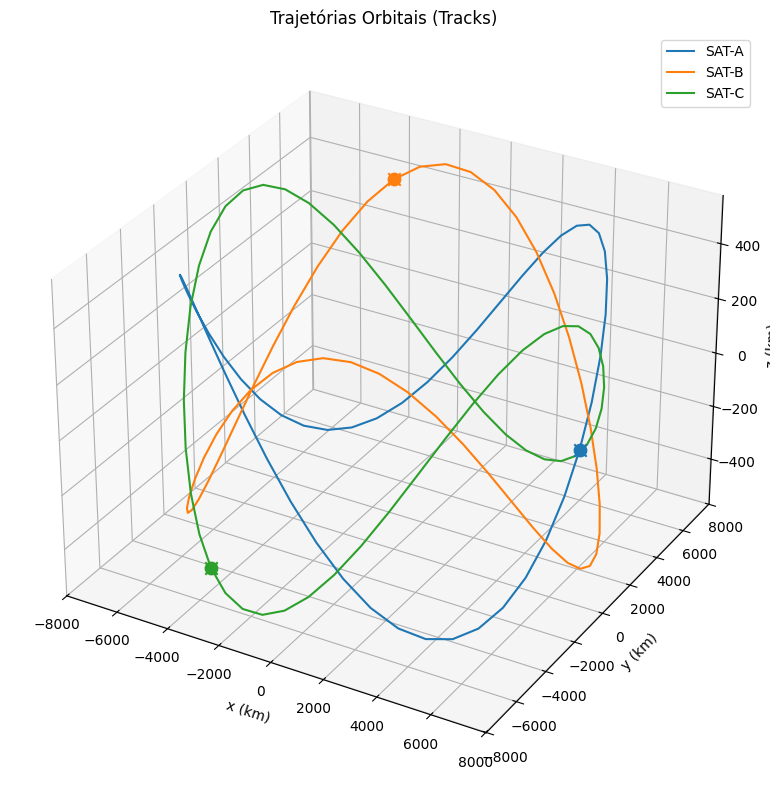

In [7]:
# ═══════════════════════════════════════════════
# 5a. Trajetórias 3D dos satélites
# ═══════════════════════════════════════════════
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")

colors = ["tab:blue", "tab:orange", "tab:green"]
for i in range(n_sats):
    pos = tracks.dataset["positions"].values[i]
    ax.plot(
        pos[:, 0],
        pos[:, 1],
        pos[:, 2],
        color=colors[i],
        label=tracks.satellite_names[i],
    )
    ax.scatter(*pos[0], color=colors[i], s=80, marker="o")
    ax.scatter(*pos[-1], color=colors[i], s=80, marker="x")

ax.set_xlabel("x (km)")
ax.set_ylabel("y (km)")
ax.set_zlabel("z (km)")
ax.set_title("Trajetórias Orbitais (Tracks)")
ax.legend()
plt.tight_layout()
plt.show()

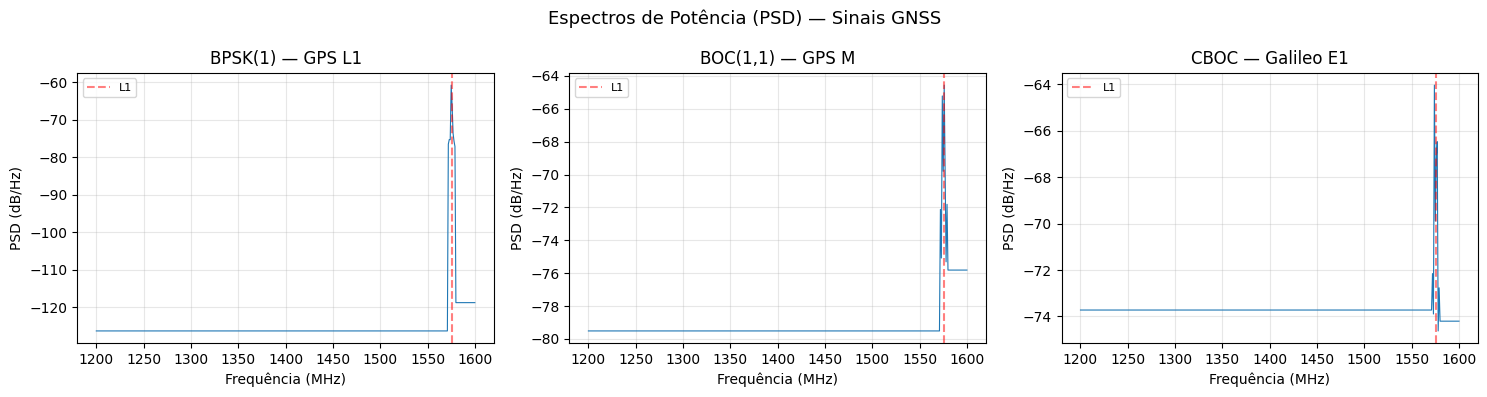

In [10]:
# ═══════════════════════════════════════════════
# 5b. PSDs das modulações GNSS
# ═══════════════════════════════════════════════
# Re-computa PSDs com o grid de 1200-1600 MHz para visualização
fr_viz = FrequencyRange(min_mhz=1200.0, max_mhz=1600.0, resolution_mhz=1.0)
mock_repo_viz = MagicMock()
sf_viz = SignalFactory(frequency_range=fr_viz, signal_repo=mock_repo_viz)
grid_viz = sf_viz.frequency_grid_hz() * 1e-6  # MHz

psd_bpsk_viz = sf_viz._simulate_psd(
    modulation="BPSK(1)", fc_hz=1575.42e6, prn_len=2048, fs_factor=8
).compute()

psd_boc_viz = sf_viz._simulate_psd(
    modulation="BOC(1,1)", fc_hz=1575.42e6, prn_len=2048, fs_factor=8
).compute()

psd_cboc_viz = sf_viz._simulate_psd(
    modulation="CBOC", fc_hz=1575.42e6, prn_len=2048, fs_factor=8
).compute()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

titles = ["BPSK(1) — GPS L1", "BOC(1,1) — GPS M", "CBOC — Galileo E1"]
psds_viz = [psd_bpsk_viz, psd_boc_viz, psd_cboc_viz]

for ax, title, psd_data in zip(axes, titles, psds_viz):
    ax.plot(grid_viz, psd_data, linewidth=0.8)
    ax.set_xlabel("Frequência (MHz)")
    ax.set_ylabel("PSD (dB/Hz)")
    ax.set_title(title)
    ax.axvline(1575.42, color="red", linestyle="--", alpha=0.5, label="L1")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.suptitle("Espectros de Potência (PSD) — Sinais GNSS", fontsize=13)
plt.tight_layout()
plt.show()

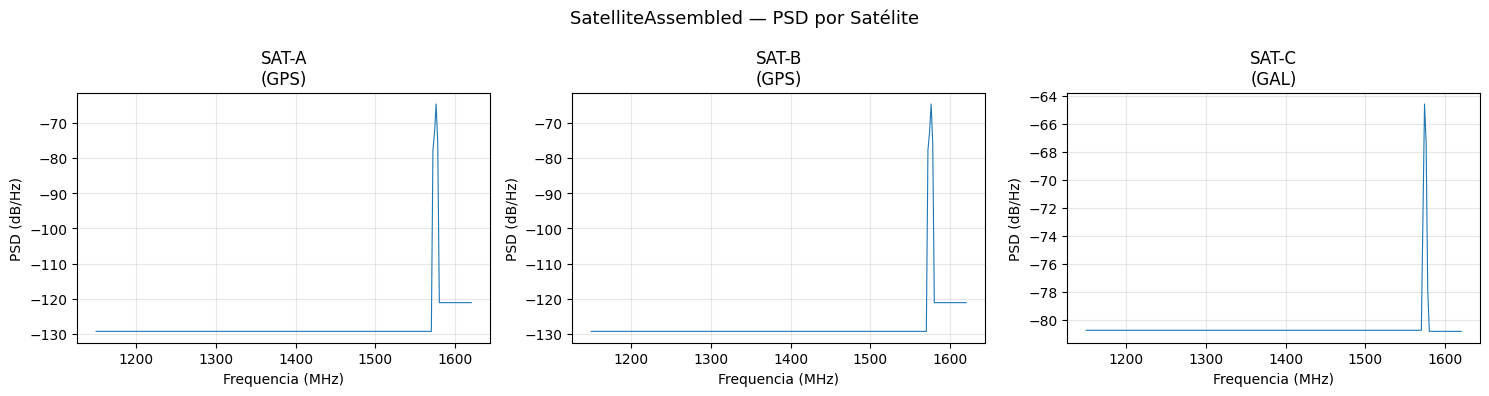

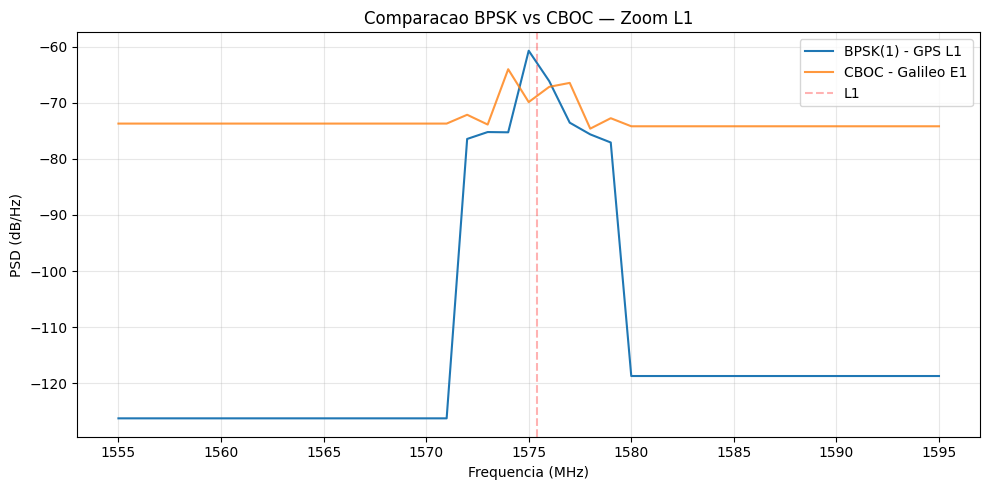

In [ ]:
# ═══════════════════════════════════════════════
# 5c. SatelliteAssembled — PSD por satélite
# ═══════════════════════════════════════════════
fig, axes = plt.subplots(1, n_sats, figsize=(15, 4))

for i, a in enumerate(assembled_list):
    psd_values = a.psd().values
    freq_values = a.signals["freq"].values
    axes[i].plot(freq_values, psd_values, linewidth=0.8)
    axes[i].set_xlabel("Frequencia (MHz)")
    axes[i].set_ylabel("PSD (dB/Hz)")
    axes[i].set_title(f"{a.name}\n({track_ds.constellation.values[i]})")
    axes[i].grid(True, alpha=0.3)

plt.suptitle("SatelliteAssembled — PSD por Satélite", fontsize=13)
plt.tight_layout()
plt.show()

# ═══════════════════════════════════════════════
# 5d. Comparação BPSK vs CBOC (zoom)
# ═══════════════════════════════════════════════
fig, ax = plt.subplots(figsize=(10, 5))

# Zoom na região central (±5 MHz em torno de 1575.42 MHz)
center_idx = np.argmin(np.abs(grid_viz - 1575.42))
zoom = slice(max(0, center_idx - 20), min(len(grid_viz), center_idx + 21))

ax.plot(grid_viz[zoom], psd_bpsk_viz[zoom], label="BPSK(1) - GPS L1", linewidth=1.5)
ax.plot(
    grid_viz[zoom],
    psd_cboc_viz[zoom],
    label="CBOC - Galileo E1",
    linewidth=1.5,
    alpha=0.8,
)
ax.axvline(1575.42, color="red", linestyle="--", alpha=0.3, label="L1")
ax.set_xlabel("Frequencia (MHz)")
ax.set_ylabel("PSD (dB/Hz)")
ax.set_title("Comparacao BPSK vs CBOC — Zoom L1")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 6. ✅ Análise e Validação do Fluxo

Verificações de consistência: validação estrutural dos modelos, integridade dos dados e métricas do pipeline.


In [ ]:
# ═══════════════════════════════════════════════
# 6a. Validação estrutural dos modelos
# ═══════════════════════════════════════════════

# Re-cria Satellite para validação (foi sobrescrito em células anteriores)
sat_valid = Satellite(
    norad_id=25544,
    name="ISS (ZARYA)",
    constellation="ISS",
    epoch=epoch,
    element=orb,
)
assert isinstance(sat_valid, Satellite)
assert sat_valid.norad_id == 25544
assert sat_valid.element.norad_id == orb.norad_id
print("✅ Satellite: modelo válido, validação de época ok")

# SignalDefinition
assert gps_l1.modulation == "BPSK(1)"
assert gps_l1.frequency == 1575.42
print("✅ SignalDefinition: modelagem correta")

# SatSignal
assert sat_sig.signal.modulation == "BPSK(1)"
print("✅ SatSignal: vinculação SignalDefinition ok")

# Tracks
assert tracks.dataset.sizes["satellite"] == n_sats
assert tracks.dataset.sizes["time"] == n_times
assert tracks.dataset.sizes["xyz"] == 3
print("✅ Tracks: validação de dimensões ok")

# ═══════════════════════════════════════════════
# 6b. Integridade dos dados gerados
# ═══════════════════════════════════════════════

# PSD: valores finitos
assert np.all(np.isfinite(psd_bpsk_viz)), "PSD BPSK contém NaN/Inf"
assert np.all(np.isfinite(psd_cboc_viz)), "PSD CBOC contém NaN/Inf"
print(f"✅ PSDs: todos os valores finitos")
print(
    f"   BPSK(1): min={psd_bpsk_viz.min():.1f} dB/Hz, max={psd_bpsk_viz.max():.1f} dB/Hz"
)
print(
    f"   CBOC:    min={psd_cboc_viz.min():.1f} dB/Hz, max={psd_cboc_viz.max():.1f} dB/Hz"
)

# Tracks: posições realistas (órbita ~7000 km)
mean_r = np.mean(np.linalg.norm(tracks.dataset["positions"].values, axis=2))
print(f"   Raio orbital médio: {mean_r:.0f} km (esperado ~7000 km)")

# ═══════════════════════════════════════════════
# 6c. Métricas do pipeline
# ═══════════════════════════════════════════════
print(f"\n📊 Métricas do fluxo end-to-end:")
print(f"   • {n_sats} satélites modelados")
print(f"   • {n_times} amostras temporais por satélite")
print(f"   • {len(grid_viz)} pontos de frequência no grid de visualização")
print(f"   • {n_sats} SatelliteAssembled montados")
print(f"\n🎯 Fluxo completo: Satellite → Tracks → Signal → Assembled → OK")

✅ Satellite: modelo válido, validação de época ok
✅ SignalDefinition: modelagem correta
✅ SatSignal: vinculação SignalDefinition ok
✅ Tracks: validação de dimensões ok
✅ PSDs: todos os valores finitos
   BPSK(1): min=-126.2 dB/Hz, max=-60.7 dB/Hz
   CBOC:    min=-74.6 dB/Hz, max=-64.0 dB/Hz
   Raio orbital médio: 7009 km (esperado ~7000 km)

📊 Métricas do fluxo end-to-end:
   • 3 satélites modelados
   • 50 amostras temporais por satélite
   • 401 pontos de frequência no grid de visualização
   • 3 SatelliteAssembled montados

🎯 Fluxo completo: Satellite → Tracks → Signal → Assembled → OK
